# 5 GSPS MIMO loopback on the ZCU208 (`mimo_mts_5g`)

A tutorial walk through the `MIMO5G_ZCU208` overlay: load a waveform, play it on all 8 RF-DACs at 5 GSPS, capture
it on all 8 RF-ADCs through loopback cables, and check what came back: the digital DAC copy, latency, channel
alignment, spectrum, phase continuity over the capture, and baseband after the mixers.

**Hardware.** ZCU208 with CLK104, one equal-length cable from each DAC to the ADC of the same number
(DAC *n* → ADC *n*, *n* = 0…7). Copy `mimo_mts_5g.bit` and `.hwh` to `mimo_mts/overlays/zcu208/` on the board.

## How the samples move

| Path | Width and clock | Memory |
|---|---|---|
| DAC | `wave_gen`: 320-bit rows (20 int16) at 250 MHz → 160 bits at 500 MHz → broadcaster → 8 DACs | 4096 rows: 81,920 int16 = 40,960 I/Q pairs = 16.4 µs (complex 2.5 GSPS, interpolation 2) |
| DAC copy | the broadcast stream → `hier_dac_cap` (`axi_wave_cap`) | 2048 rows |
| ADC | RFDC 160 bits at 500 MHz → 2:1 to 320 bits at 250 MHz → `axi_wave_cap`, one per I and Q stream (16) | 2048 rows: 40,960 samples = 8.2 µs at 5 GSPS |

Software sees each memory as a flat int16 array in sample order; the width conversion between the power-of-two AXI
bus and the 320-bit rows is done by the address mapping (design notes: `doc/wave_gen.md`). All 8 DACs currently play
the same waveform; one generator per DAC is planned (`doc/development_plan.md`, item 2).

In [1]:
%cd /home/xilinx/jupyter_notebooks/pynq_llrf/

/home/xilinx/jupyter_notebooks/pynq_llrf


In [2]:
import asyncio
import time

import matplotlib.pyplot as plt
import numpy as np

from mimo_mts.overlay import MimoMtsOverlay
from mimo_mts.utils.plot import plot_adc_psd, plot_complex_wfm_stack

%load_ext autoreload
%autoreload 2

In [3]:
ol = MimoMtsOverlay(config="MIMO5G_ZCU208")
ol

< MimoMtsOverlay >:
{ 'bitfile_name': PosixPath('/home/xilinx/jupyter_notebooks/pynq_llrf/mimo_mts/overlays/zcu208/mimo_mts_5g.bit'),
  'board': Board(name='ZCU208',
                 active_adc_tiles=15,
                 active_dac_tiles=15,
                 max_adc_sampling_rate=5000000000.0,
                 max_dac_sampling_rate=7000000000.0,
                 converters_per_tile=2,
                 adc_ref_tile=225,
                 dac_ref_tile=230),
  'clk104_tcs': { 'lmk_tcs': PosixPath('/home/xilinx/jupyter_notebooks/pynq_llrf/mimo_mts/utils/clk104/LMK04828_500M_CLKin0.tcs'),
                  'lmxadc_tcs': PosixPath('/home/xilinx/jupyter_notebooks/pynq_llrf/mimo_mts/utils/clk104/LMX2594_5G.tcs'),
                  'lmxdac_tcs': PosixPath('/home/xilinx/jupyter_notebooks/pynq_llrf/mimo_mts/utils/clk104/LMX2594_5G.tcs')},
  'ioc': {'decimation': 20},
  'rfdc': { 'adc_decimation_factor': 1,
            'dac_interpolation_factor': 2,
            'mixer': { 'adc_mixer_mode': 3,
     

In [4]:
fs = ol.adc_sampling_rate  # 5 GSPS, ADC and DAC
fs_ghz = fs / 1e9
fs_iq = ol.dac_sampling_rate / 2  # complex rate of the DAC input (interpolation 2)
f_dsp = 250e6  # rf_control, wave_gen and capture clock
n_adc = ol.board.n_adcs
print(f"fs = {fs_ghz} GSPS; DAC input {fs_iq / 1e9} GSPS complex")
print(f"generator: {ol.wave_gen.wave_mem.size} int16 = {ol.wave_gen.wave_mem.size / 2 / fs_iq * 1e6:.1f} us")
print(f"ADC capture: {ol.adc_bufs[0].size} samples = {ol.adc_bufs[0].size / fs * 1e6:.1f} us per stream")

fs = 5.0 GSPS; DAC input 2.5 GSPS complex
generator: 81920 int16 = 16.4 us
ADC capture: 40960 samples = 8.2 us per stream


## Trigger and captures

`axil_rf_control` makes the trigger (internal, 10 Hz here). The generator and all 17 captures start on it. The
generator plays the whole memory (`wave_length = 0`), the captures record `pulse_length` rows (clamped to their
2048-row depth).

At high trigger rates a capture can be overwritten while it is being read. Two ways to avoid that:
**one-shot mode** (capture once per `ol.arm_captures()`, then hold until read) and the **capture-done interrupt**
(`ol.write_done_irq`). Both need a bitstream from commit b751729 or later; `capture()` below falls back to waiting a
few trigger periods on older ones.

In [5]:
period_s = 0.1
rc = ol.rf_control.register_map
rc.trig_sel = 0  # internal trigger
rc.trig_period = int(period_s * f_dsp)
rc.trig_delay = 0
rc.trig_divide = 1
rc.dac_enable = 1
rc.pulse_length = 0xFFFF  # capture rows, clamped to 2048
ol.wave_gen.trigger_mode = 1  # play on the rf_control trigger
ol.wave_gen.wave_length = 0  # play all 4096 rows

In [6]:
HAS_CAPTURE_CSR = True


def capture(timeout_s=1.0):
    """Fresh captures on the next trigger: one-shot arm/done if available, else wait a few trigger periods."""
    if not HAS_CAPTURE_CSR:
        time.sleep(3 * period_s + 0.05)
        return True
    ol.capture_oneshot = True
    ol.arm_captures()
    return ol.wait_captures(timeout_s)

In [7]:
async def wait_irqs(n=5):
    irq = ol.write_done_irq
    t0 = time.perf_counter()
    for _ in range(n):
        await irq.wait()
        t1 = time.perf_counter()
        print(f"capture done, {t1 - t0:.4f} s since the last")
        t0 = t1


if hasattr(ol, "write_done_irq"):
    ol.capture_oneshot = False  # capture on every trigger for this test
    asyncio.get_event_loop().run_until_complete(wait_irqs())
else:
    print("no capture interrupt in this bitstream")

capture done, 0.0010 s since the last
capture done, 0.0162 s since the last
capture done, 0.1001 s since the last
capture done, 0.1002 s since the last
capture done, 0.0998 s since the last


## 1. Load a waveform

A 200 MHz complex tone, 2 µs long with raised-cosine edges, followed by zeros. The DAC interpolates by 2 and the
fine mixer is at 0 Hz, so each DAC outputs a real 200 MHz burst. `write_dac_complex` interleaves I and Q into the
generator memory; any write size or order works and no flush is needed.

Text(0.5, 1.0, 'written waveform (I)')

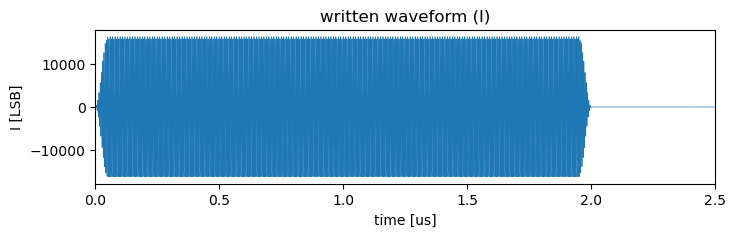

In [8]:
n_iq = ol.wave_gen.wave_mem.size // 2
t_iq = np.arange(n_iq) / fs_iq
f_c = 200e6
pulse_s, edge_s = 2e-6, 50e-9
env = np.clip(np.minimum(t_iq, pulse_s - t_iq) / edge_s, 0, 1)
env = 0.5 - 0.5 * np.cos(np.pi * env)  # raised-cosine edges
amp = 0.5 * (2**15 - 1)
dac_wfm = amp * env * np.exp(2j * np.pi * f_c * t_iq)


def load_burst():
    """Mixers at 0 Hz and the 200 MHz burst in the generator (sections 2-4 call this, so they can run in any order)."""
    ol.set_dac_mixer(freq_mhz=0)
    ol.set_adc_mixer(freq_mhz=0)
    ol.write_dac_complex(dac_wfm)


load_burst()

plt.figure(figsize=(8, 2))
plt.plot(t_iq * 1e6, dac_wfm.real, lw=0.5)
plt.xlim(0, 2.5)
plt.xlabel("time [us]")
plt.ylabel("I [LSB]")
plt.title("written waveform (I)")

## 2. The DAC copy

`hier_dac_cap` records the 160-bit stream that the broadcaster sends to the DACs, so it must equal the written
waveform bit for bit (from the first played row). This checks the generator, the width conversions and the capture
core without any analog path.

DAC copy bit-exact: True (starts 0 words = 0 rows into the playback)
non-zero words in the copy: 9799 of 40960 (the burst is the first 500 rows)


Text(0.5, 0, 'time [us]')

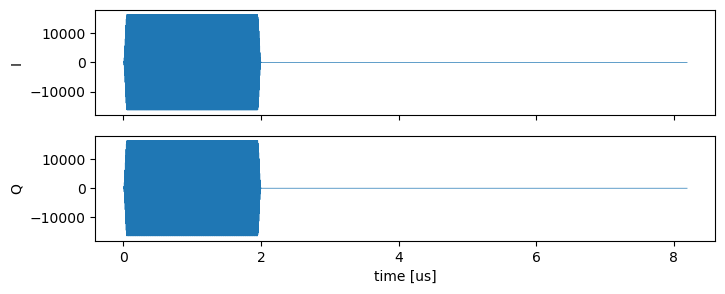

In [9]:
load_burst()
capture()
dac_i, dac_q = ol.capture_dac_iq_buf()
written = np.empty(2 * n_iq, dtype=np.int16)
written[0::2] = dac_wfm.real.astype(np.int16)  # as write_dac_iq_buf converts (truncation, not rounding)
written[1::2] = dac_wfm.imag.astype(np.int16)
cap = np.array(ol.dac_capture)
# the tone repeats on the plateau, so try every I/Q-pair offset and keep the one where the whole capture matches
k = next((k for k in range(0, written.size - cap.size + 1, 2) if np.array_equal(cap, written[k : k + cap.size])), None)
print(
    "DAC copy bit-exact:",
    k is not None,
    f"(starts {k} words = {k / 20:g} rows into the playback)" if k is not None else "",
)
print(f"non-zero words in the copy: {np.count_nonzero(cap)} of {cap.size} (the burst is the first 500 rows)")

t_cap = np.arange(dac_i.size) / fs_iq
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(8, 3))
ax[0].plot(t_cap * 1e6, dac_i, lw=0.5)
ax[0].set_ylabel("I")
ax[1].plot(t_cap * 1e6, dac_q, lw=0.5)
ax[1].set_ylabel("Q")
ax[1].set_xlabel("time [us]")

## 3. Loopback: all 8 ADCs

With the ADC mixer at 0 Hz, I holds the real 5 GSPS samples (Q is 0). The burst arrives after the loopback latency:
DAC and ADC pipelines plus the cable. With multi-tile sync (MTS) and equal cables the latency is the same on every
channel and on every overlay load.

ADC0: burst starts at sample 1028 = 205.6 ns after the capture start
ADC1: burst starts at sample 1028 = 205.6 ns after the capture start
ADC2: burst starts at sample 1029 = 205.8 ns after the capture start
ADC3: burst starts at sample 1028 = 205.6 ns after the capture start
ADC4: burst starts at sample 1029 = 205.8 ns after the capture start
ADC5: burst starts at sample 1029 = 205.8 ns after the capture start
ADC6: burst starts at sample 1029 = 205.8 ns after the capture start
ADC7: burst starts at sample 1028 = 205.6 ns after the capture start


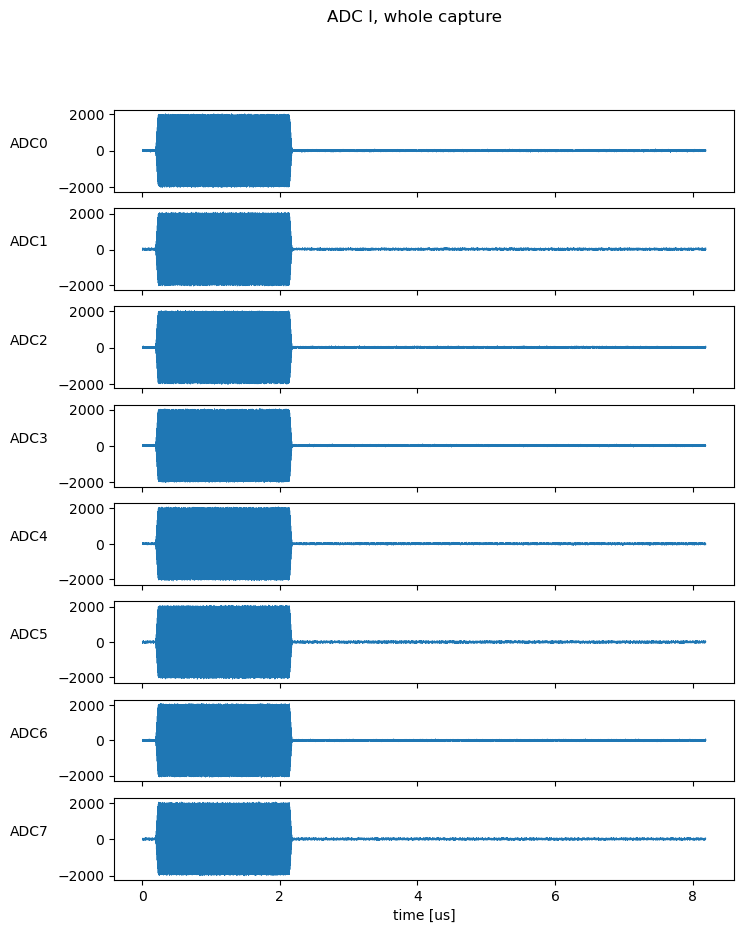

In [10]:
load_burst()
capture()
adc_i, adc_q = ol.capture_adc_iq_buf()
t_adc = np.arange(adc_i.shape[1]) / fs

fig, axes = plt.subplots(n_adc, 1, sharex=True, figsize=(8, 10))
for ch, ax in enumerate(axes):
    ax.plot(t_adc * 1e6, adc_i[ch], lw=0.4)
    ax.set_ylabel(f"ADC{ch}", rotation=0, labelpad=20)
axes[-1].set_xlabel("time [us]")
fig.suptitle("ADC I, whole capture")

onset = [int(np.argmax(np.abs(x) > 0.3 * np.abs(x).max())) for x in adc_i]
for ch, n in enumerate(onset):
    print(f"ADC{ch}: burst starts at sample {n} = {n / fs_ghz:.1f} ns after the capture start")

Text(0.5, 0.98, 'rising edge of the burst')

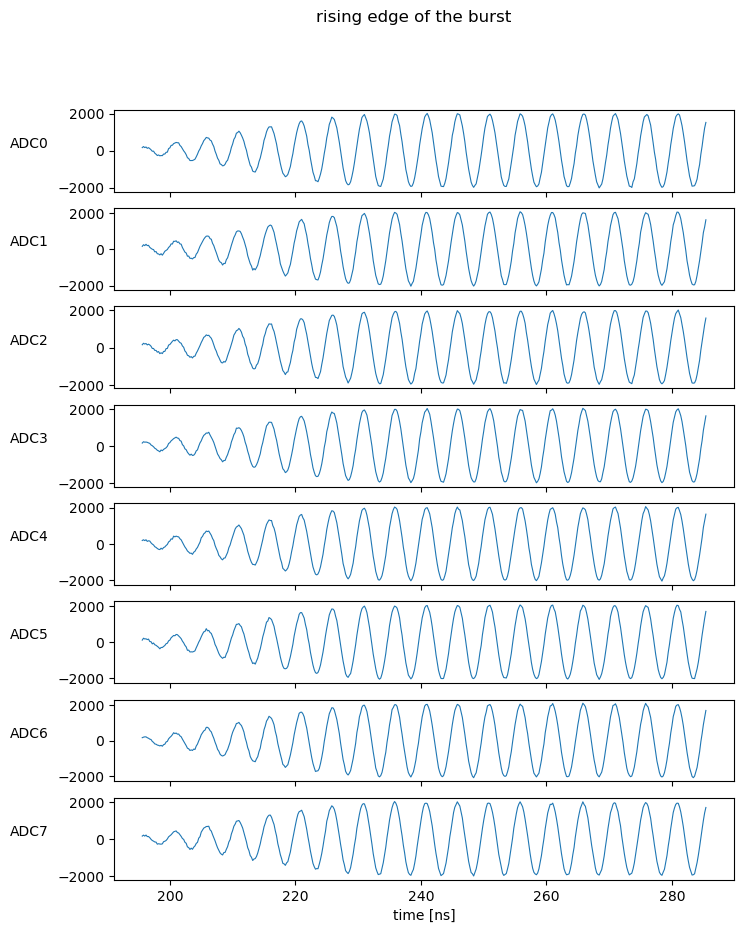

In [11]:
n0 = min(onset)
fig, axes = plt.subplots(n_adc, 1, sharex=True, figsize=(8, 10))
for ch, ax in enumerate(axes):
    ax.plot(t_adc[n0 - 50 : n0 + 400] * 1e9, adc_i[ch, n0 - 50 : n0 + 400], lw=0.8)
    ax.set_ylabel(f"ADC{ch}", rotation=0, labelpad=20)
axes[-1].set_xlabel("time [ns]")
fig.suptitle("rising edge of the burst")

## 4. Channel alignment

Two measures per channel, both against ADC0: the rising edge of the burst (50 % of the envelope, averaged over one
carrier period and interpolated; good to a fraction of a sample, 200 ps) and the phase of the 200 MHz carrier on the
flat top of the burst (picoseconds; the edge resolves its 5 ns ambiguity). With MTS and equal cables both stay at a
fixed value from capture to capture; the carrier delays show the cable and channel skews.

In [12]:
def edge_times(adc_i, smooth=25):
    """Burst rising edge per channel [samples]: 50 % crossing of the envelope, averaged over one carrier period
    (25 samples at 200 MHz) and interpolated between samples. None if the capture holds no burst edge."""
    k = np.ones(smooth) / smooth
    out = []
    for x in adc_i:
        env = np.convolve(np.abs(x.astype(float)), k, mode="same")
        half = 0.5 * np.percentile(env, 99)
        above = np.flatnonzero(env >= half)
        if above.size == 0 or above[0] == 0 or env.max() < 1000:
            out.append(None)
            continue
        n = above[0]
        out.append(n - 1 + (half - env[n - 1]) / (env[n] - env[n - 1]))
    return out


def carrier_delays_ps(adc_i, t_edge, f=f_c, settle=100e-9, length=1e-6):
    """Delay vs ADC0 from the carrier phase on the flat top of the burst [ps]; unambiguous within +-1/(2f) = 2.5 ns,
    which the edge times already resolve."""
    n0 = int(t_edge + settle * fs)
    n = np.arange(n0, n0 + int(length * fs))
    ph = np.array([np.angle(np.sum(x[n] * np.exp(-2j * np.pi * f * n / fs))) for x in adc_i.astype(float)])
    dph = np.angle(np.exp(1j * (ph - ph[0])))
    return -dph / (2 * np.pi * f) * 1e12


load_burst()
for run in range(3):
    capture()
    adc_i, _ = ol.capture_adc_iq_buf()
    t = edge_times(adc_i)
    if t[0] is None:
        print(f"run {run}: no burst edge in this capture")
        continue
    print(f"run {run}: edge at {t[0] / fs_ghz:.1f} ns")
    print("   edge delay vs ADC0 [samples]:   ", [None if x is None else round(x - t[0], 2) for x in t])
    print("   carrier delay vs ADC0 [ps]:     ", np.round(carrier_delays_ps(adc_i, t[0]), 1).tolist())

run 0: edge at 210.8 ns
   edge delay vs ADC0 [samples]:    [0.0, 0.68, 1.32, 0.11, 0.72, 1.43, 1.0, 0.96]
   carrier delay vs ADC0 [ps]:      [-0.0, -24.8, -19.5, -9.6, -43.7, -44.9, -43.7, -110.5]
run 1: edge at 211.0 ns
   edge delay vs ADC0 [samples]:    [0.0, -0.3, -1.08, -0.31, -0.33, -0.08, -0.81, -0.48]
   carrier delay vs ADC0 [ps]:      [-0.0, -25.0, -19.5, -9.9, -43.8, -44.9, -43.6, -110.3]
run 2: edge at 210.9 ns
   edge delay vs ADC0 [samples]:    [0.0, -0.28, 0.67, -0.05, 0.96, 0.2, 0.77, 1.46]
   carrier delay vs ADC0 [ps]:      [-0.0, -25.0, -19.3, -9.9, -43.3, -44.5, -43.4, -109.8]


## 5. A CW tone from the DAC NCO, and its spectrum

Write a constant I/Q value and let the DAC fine mixer (NCO) make the tone: the waveform memory then plays DC and
the tone is continuous over the whole capture. The spectrum shows the tone, its harmonics, and the RF-ADC
interleaving spurs (offset spurs at multiples of Fs/8, gain/time-skew images at k·Fs/8 − f; see
`doc/adc_calibration_findings.md`).

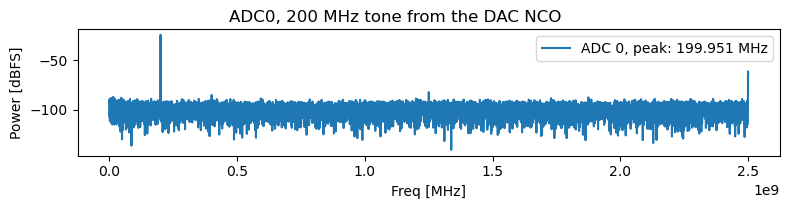

In [13]:
dc = np.full(n_iq, 0.5 * (2**15 - 1), dtype=complex)
ol.write_dac_complex(dc)
ol.set_dac_mixer(freq_mhz=f_c / 1e6)
capture()
adc_i, _ = ol.capture_adc_iq_buf()
plot_adc_psd(adc_i[:1], fs=fs, title="ADC0, 200 MHz tone from the DAC NCO")

## 6. Phase continuity over the 8.2 µs capture

Demodulate each channel at the tone frequency in 40 ns blocks and remove a linear phase fit. A capture without lost
or repeated rows stays flat; one missing 20-sample row (4 ns) would show as a 288° step at 200 MHz. The same check
runs in `mimo_mts/tests/test_mimo5g.py`.

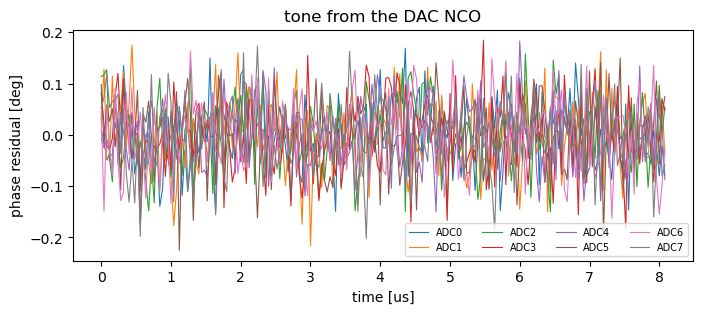

In [14]:
def phase_residual(x, fs, block=200):
    x = x.astype(float)
    spec = np.abs(np.fft.rfft(x * np.hanning(x.size)))
    f0 = np.argmax(spec) * fs / x.size
    z = x * np.exp(-2j * np.pi * f0 * np.arange(x.size) / fs)
    nb = x.size // block
    ph = np.unwrap(np.angle(z[: nb * block].reshape(nb, block).mean(axis=1)))
    k = np.arange(nb)
    return k * block / fs, np.degrees(ph - np.polyval(np.polyfit(k, ph, 1), k))


def plot_continuity(adc_i, title):
    plt.figure(figsize=(8, 3))
    for ch, x in enumerate(adc_i):
        t, r = phase_residual(x[200:], fs)
        plt.plot(t * 1e6, r, lw=0.8, label=f"ADC{ch}")
    plt.xlabel("time [us]")
    plt.ylabel("phase residual [deg]")
    plt.title(title)
    plt.legend(ncol=4, fontsize=7)


plot_continuity(adc_i, "tone from the DAC NCO")

For comparison, the same tone generated by `wave_gen` (the DAC NCO back at 0 Hz). With the first `mimo_mts_5g`
build this showed a phase step at a random time, identical on all channels: an open issue in the shared DAC
stream, not in the captures (which stay flat with the NCO tone above).

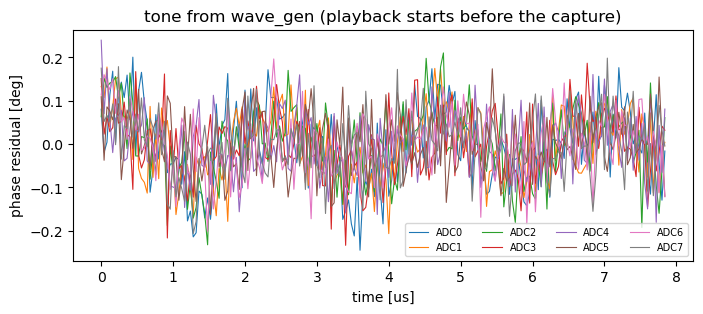

In [15]:
ol.set_dac_mixer(freq_mhz=0)
ol.write_dac_complex(amp * np.exp(2j * np.pi * f_c * t_iq))
capture()
adc_i, _ = ol.capture_adc_iq_buf()
plot_continuity(adc_i[:, 1200:], "tone from wave_gen (playback starts before the capture)")

## 7. Baseband after the mixers

Shift the burst to an intermediate frequency with the DAC NCO and back to baseband with the ADC NCO, then average
20 samples (250 MSPS, the DSP rate). Amplitude and phase should be the same on all channels.

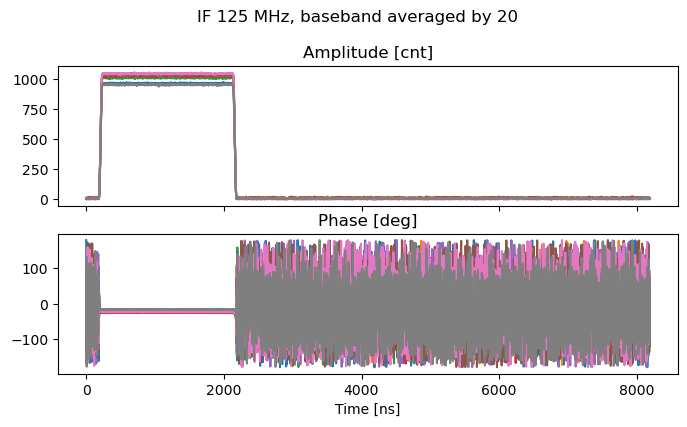

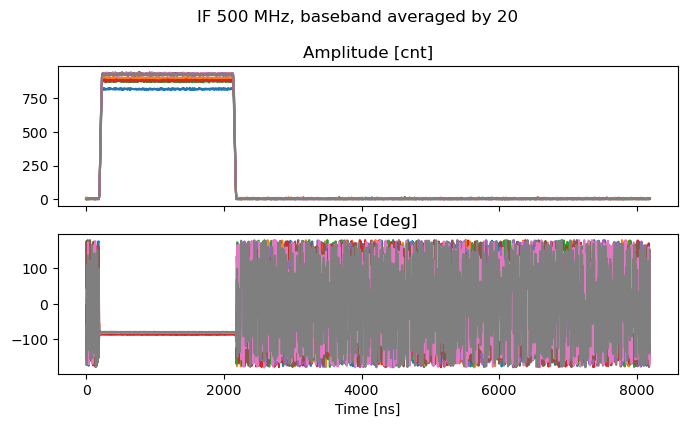

In [16]:
ol.write_dac_complex((amp * env).astype(complex))  # the 2 us burst at baseband
for f_if in (125, 500):
    ol.set_dac_mixer(freq_mhz=f_if)
    ol.set_adc_mixer(freq_mhz=-f_if)
    capture()
    adc_i, adc_q = ol.capture_adc_iq_buf()
    cdata = (adc_i + 1j * adc_q).reshape(n_adc, -1, 20).mean(axis=2)
    plot_complex_wfm_stack(cdata, fs=fs / 20, mode="ap", title=f"IF {f_if} MHz, baseband averaged by 20")

In [17]:
# restore the defaults
ol.set_dac_mixer(freq_mhz=0)
ol.set_adc_mixer(freq_mhz=0)
if HAS_CAPTURE_CSR:
    ol.capture_oneshot = False

## Notes

- Bit-exact and continuity checks without plots: `sudo -E python3 mimo_mts/tests/test_mimo5g.py --repeat 3 --nco`.
- The generator, capture and their memory layout: `doc/wave_gen.md`; plans (one generator per DAC):
  `doc/development_plan.md`, item 2.